# p2.1: deliberation against people — network-ordered AND-OR on the human layouts

*Part of phase 2: `p2_summary.ipynb` connects this notebook with p2.1-p2.3.*

The intuition–deliberation analyses so far measured the apprentice mostly by **intuition** alone (the policy head
playing every move; summary notebook, "Expert Iteration"). This notebook takes the other end: **deliberation only** —
AND-OR search whose candidate moves are ordered by the apprentice's dest head (`student.PolicyAgent.heuristic`, Gumbel noise
at temperature 1 as during expert iteration), with lapse rate $\gamma$ — the threshold > 1 end of
`student.solve_arbitrated`. It is compared with people, with plain (randomly ordered) AND-OR, and with the same checkpoints
playing by intuition.

**Runs** (`experiments/and_or_network.py` → `models/summary/and_or_network/`): the four kept checkpoints of
`models/apprentice/gamma0.07_free` (untrained, rounds 1–3) each play the 70 layouts people played, 20 times per
layout, at $\gamma \in \{0.01, 0.035, 0.07, 0.15, 0.3\}$, exactly as `experiments/and_or_gamma.py` plays plain AND-OR
(whole plans, protect_movers off, a cap of 10× the optimal length, at least 50 moves, no giving up). The same
checkpoints also play every layout 20 times by intuition alone (policy head at temperature 1, memory 10, same cap).

**Scoring**, as in the summary notebook: each human trial is predicted by the model's runs on that very layout, with
people's giving up applied afterwards from the move count (`hd.surrender_hazard`, scale 1). Predictions are averaged
per person and then across people, as people's own numbers are. The target is people's **first 10 trials**
(the apprentice is the student before any session learning; the models don't learn between trials, so only people's
side changes with the block).

In [1]:
import sys
sys.path.insert(0, "..")
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rushhour import human_data as hd, surrender as fs

RUNS = "../models/summary/and_or_network"  # written by experiments/and_or_network.py
PLAIN = "../models/sessions/and_or_gamma/sweep.csv"  # plain AND-OR, experiments/and_or_gamma.py
FIGURES = "../visualization/p8_deliberation"
os.makedirs(FIGURES, exist_ok=True)
LENGTHS = (6, 10, 13, 15)
BLOCK = 10  # people's first BLOCK trials are the target
FINAL = "round3_epoch01"  # the last kept checkpoint
FOCUS_GAMMA = 0.035  # the best gamma for the trained network (below)
CHECKPOINTS = {"round0_epoch00": "untrained", "round1_epoch05": "round 1", "round2_epoch02": "round 2",
               "round3_epoch01": "round 3"}

INK, MUTED, RULE, GRID = "#1f1f1d", "#5f5e5a", "#b5b4ad", "#e6e5e0"
PEOPLE, MODEL, ACCENT, INTUITION = "#8a8a85", "#2a78d6", "#e6550d", "#1baf7a"  # as in p1_summary.ipynb
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 110,
                     "legend.frameon": False, "legend.fontsize": 8.5})


def tidy(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def mean_se(v):
    v = np.asarray([x for x in v if x == x], float)
    return v.mean(), v.std(ddof=1) / np.sqrt(len(v))

## Scoring every model against people

`expected` turns a layout's runs into the chance a person-like player solves it (each solved run survives people's
giving-up hazard up to its move count) and the moves / optimal of the solves that survive; `raw_solve` is the share
solved within the cap with no giving up. `score` predicts every human trial from its layout and averages per person,
then across people, per length and over all lengths.

In [2]:
humans = hd.trials()
target = humans[humans.trial <= BLOCK]
EDGES, RATES, _ = hd.surrender_hazard()


def expected(group):
    d = group.distance.iloc[0]
    w = np.array([fs.survival(int(m), d, EDGES, RATES, 1.0) if s else 0.0 for m, s in zip(group.moves, group.solved)])
    ratio = (w * group.moves / d).sum() / w.sum() if w.sum() else np.nan
    return pd.Series({"solve": w.mean(), "ratio": ratio, "raw_solve": group.solved.mean()})


def score(runs, trials=target):
    pred = trials.join(runs.groupby("instance").apply(expected, include_groups=False), on="instance")
    out = []
    for length in LENGTHS + ("all",):
        p = pred if length == "all" else pred[pred.distance == length]
        per = p.groupby("subject")[["solve", "ratio", "raw_solve"]].mean()
        out.append({"length": length, **per.mean().to_dict()})
    return out


people = target.assign(ratio=np.where(target.solved, target.moves / target.distance, np.nan),
                       solve=target.solved.astype(float))
rows = []
for length in LENGTHS + ("all",):
    p = people if length == "all" else people[people.distance == length]
    (s, sse), (r, rse) = (mean_se(p.groupby("subject")[k].mean()) for k in ("solve", "ratio"))
    rows.append({"model": "people", "checkpoint": "-", "gamma": np.nan, "length": length, "solve": s,
                 "solve_se": sse, "ratio": r, "ratio_se": rse})

network = pd.read_csv(os.path.join(RUNS, "sweep.csv"))
network["checkpoint"] = network.checkpoint.str.replace(".pt", "")
intuition = pd.read_csv(os.path.join(RUNS, "intuition.csv"))
intuition["checkpoint"] = intuition.checkpoint.str.replace(".pt", "")
plain = pd.read_csv(PLAIN)
plain = plain[~plain.protect]  # as the apprentice's expert

for gamma, d in plain.groupby(plain.gamma.round(4)):
    rows += [{"model": "plain AND-OR", "checkpoint": "-", "gamma": gamma, **x} for x in score(d)]
for (ck, gamma), d in network.groupby(["checkpoint", network.gamma.round(4)]):
    rows += [{"model": "network-ordered AND-OR", "checkpoint": ck, "gamma": gamma, **x} for x in score(d)]
for ck, d in intuition.groupby("checkpoint"):
    rows += [{"model": "intuition", "checkpoint": ck, "gamma": np.nan, **x} for x in score(d)]
res = pd.DataFrame(rows)
print(f"people: n = {target.subject.nunique()}, trials 1-{BLOCK}: {len(target)} trials")

people: n = 42, trials 1-10: 420 trials


## Over the lapse rate $\gamma$

The trained network (round 3) ordering AND-OR, against plain AND-OR, over $\gamma$; the same network playing by
intuition alone has no $\gamma$ and is drawn flat. People's first 10 trials are the grey band (mean ± se).

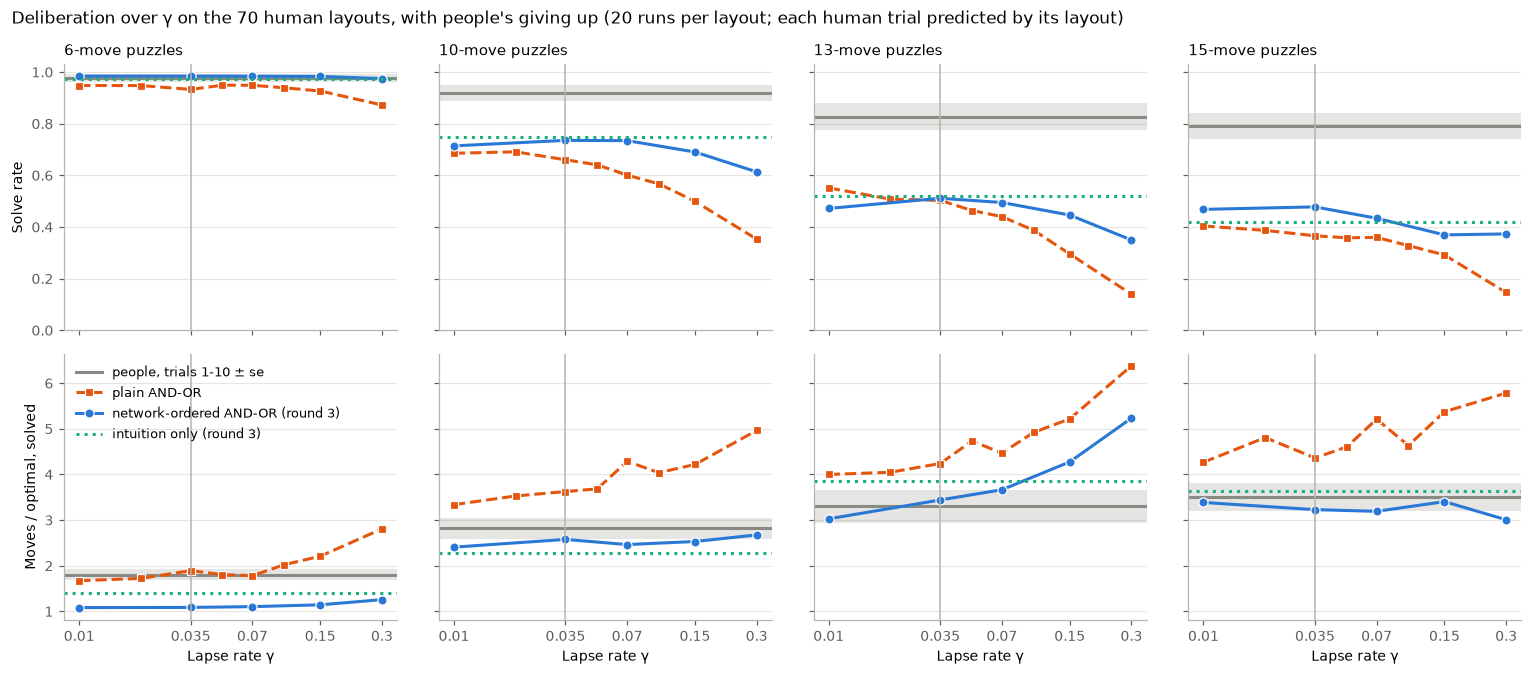

In [3]:
def series(model, checkpoint, length, column):
    d = res[(res.model == model) & (res.checkpoint == checkpoint) & (res.length == length)].sort_values("gamma")
    return d.gamma.to_numpy(), d[column].to_numpy()


GAMMA_TICKS = [0.01, 0.035, 0.07, 0.15, 0.3]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.2), sharex=True, sharey="row")
for col, length in enumerate(LENGTHS):
    for row, (column, label) in enumerate((("solve", "Solve rate"), ("ratio", "Moves / optimal, solved"))):
        ax = axes[row, col]
        p = res[(res.model == "people") & (res.length == length)].iloc[0]
        m, s = p[column], p[column + "_se"]
        ax.axhspan(m - s, m + s, color=PEOPLE, alpha=0.22, lw=0)
        ax.axhline(m, color=PEOPLE, lw=2, label=f"people, trials 1-{BLOCK} ± se")
        x, y = series("plain AND-OR", "-", length, column)
        ax.plot(x, y, "--s", color=ACCENT, lw=2, ms=5, mec="white", mew=0.8, label="plain AND-OR")
        x, y = series("network-ordered AND-OR", FINAL, length, column)
        ax.plot(x, y, "-o", color=MODEL, lw=2, ms=6, mec="white", mew=0.8, label="network-ordered AND-OR (round 3)")
        v = res[(res.model == "intuition") & (res.checkpoint == FINAL) & (res.length == length)][column].iloc[0]
        ax.axhline(v, color=INTUITION, lw=2, ls=":", label="intuition only (round 3)")
        ax.axvline(FOCUS_GAMMA, color=RULE, lw=1)
        ax.set_xscale("log")
        ax.set_xticks(GAMMA_TICKS, [f"{g:g}" for g in GAMMA_TICKS])
        ax.minorticks_off()
        if row == 0:
            ax.set_title(f"{length}-move puzzles")
        if col == 0:
            ax.set_ylabel(label)
        if row == 1:
            ax.set_xlabel("Lapse rate γ")
        tidy(ax)
axes[0, 0].set_ylim(0, 1.03)
axes[1, 0].legend(loc="upper left")
fig.suptitle("Deliberation over γ on the 70 human layouts, with people's giving up (20 runs per layout; "
             "each human trial predicted by its layout)", x=0.01, ha="left")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "gamma_sweep.png"), bbox_inches="tight")
plt.show()

## Over expert iteration: intuition vs deliberation, checkpoint by checkpoint

Every kept checkpoint at $\gamma$ = 0.035, all lengths pooled (per person over their first 10 trials). Plain AND-OR
at the same $\gamma$ doesn't learn and is drawn flat.

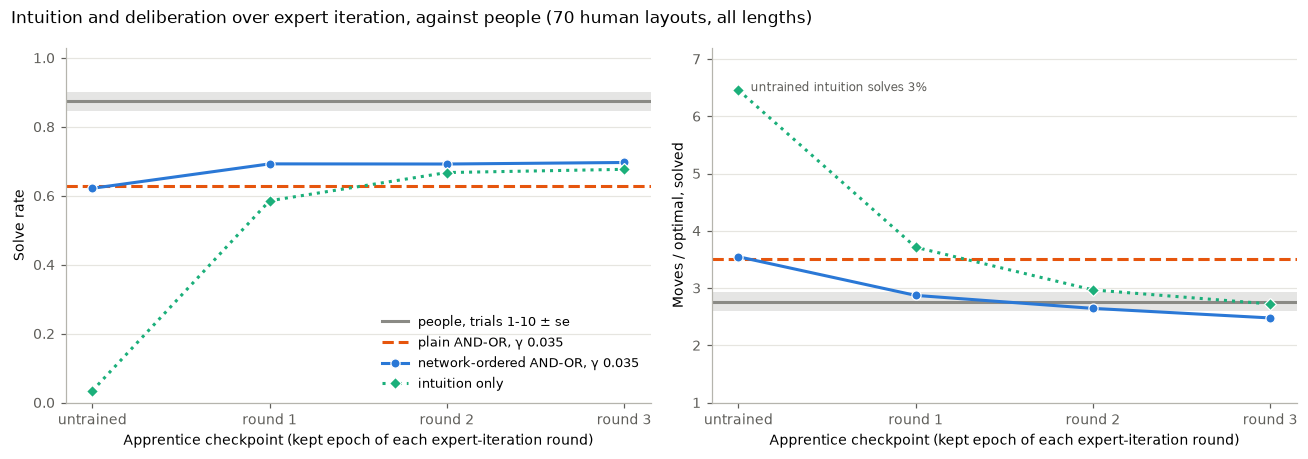

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
xs = np.arange(len(CHECKPOINTS))
for ax, (column, label) in zip(axes, (("solve", "Solve rate"), ("ratio", "Moves / optimal, solved"))):
    p = res[(res.model == "people") & (res.length == "all")].iloc[0]
    ax.axhspan(p[column] - p[column + "_se"], p[column] + p[column + "_se"], color=PEOPLE, alpha=0.22, lw=0)
    ax.axhline(p[column], color=PEOPLE, lw=2, label=f"people, trials 1-{BLOCK} ± se")
    v = res[(res.model == "plain AND-OR") & np.isclose(res.gamma, FOCUS_GAMMA) & (res.length == "all")][column].iloc[0]
    ax.axhline(v, color=ACCENT, lw=2, ls="--", label=f"plain AND-OR, γ {FOCUS_GAMMA:g}")
    for model, color, style in (("network-ordered AND-OR", MODEL, "-o"), ("intuition", INTUITION, ":D")):
        sel = res[(res.model == model) & (res.length == "all")
                  & (np.isclose(res.gamma, FOCUS_GAMMA) if model != "intuition" else True)]
        y = sel.set_index("checkpoint").loc[list(CHECKPOINTS), column]
        name = f"network-ordered AND-OR, γ {FOCUS_GAMMA:g}" if model != "intuition" else "intuition only"
        ax.plot(xs, y, style, color=color, lw=2, ms=6, mec="white", mew=0.8, label=name)
    ax.set_xticks(xs, list(CHECKPOINTS.values()))
    ax.set_xlabel("Apprentice checkpoint (kept epoch of each expert-iteration round)")
    ax.set_ylabel(label)
    tidy(ax)
axes[0].set_ylim(0, 1.03)
axes[0].legend(loc="lower right")
axes[1].set_ylim(1, 7.2)
axes[1].annotate(f"untrained intuition solves {res[(res.model == 'intuition') & (res.checkpoint == 'round0_epoch00') & (res.length == 'all')].solve.iloc[0]:.0%}",
                 (0, 6.5), xytext=(8, 0), textcoords="offset points", fontsize=8, color=MUTED, va="center")
fig.suptitle("Intuition and deliberation over expert iteration, against people (70 human layouts, all lengths)",
             x=0.01, ha="left")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "checkpoints.png"), bbox_inches="tight")
plt.show()

## The numbers

Solve rate (with people's giving up) and moves / optimal over solved trials, people's first 10 trials, by length.
People's standard errors are in the first row.

In [5]:
def fmt(r):
    return f"{r.solve:.2f} / {r.ratio:.2f}"


pick = [("people", "-", None), ("network-ordered AND-OR", FINAL, FOCUS_GAMMA), ("intuition", FINAL, None),
        ("network-ordered AND-OR", "round0_epoch00", FOCUS_GAMMA), ("plain AND-OR", "-", FOCUS_GAMMA)]
table = {}
for model, ck, gamma in pick:
    sel = res[(res.model == model) & (res.checkpoint == ck)]
    if gamma is not None:
        sel = sel[np.isclose(sel.gamma, gamma)]
    name = f"{model}" + (f" ({CHECKPOINTS.get(ck, ck)})" if ck != "-" else "") + (f", γ {gamma:g}" if gamma else "")
    table[name] = {str(r.length): fmt(r) for r in sel.itertuples()}
pse = res[res.model == "people"].set_index("length")
table["people ± se"] = {str(k): f"±{r.solve_se:.2f} / ±{r.ratio_se:.2f}" for k, r in pse.iterrows()}
display(pd.DataFrame(table).T[[str(x) for x in LENGTHS + ("all",)]].rename(columns=lambda c: f"{c} moves" if c != "all" else "all"))

,6 moves,10 moves,13 moves,15 moves,all
people,0.98 / 1.81,0.92 / 2.83,0.83 / 3.30,0.79 / 3.50,0.87 / 2.76
"network-ordered AND-OR (round 3), γ 0.035",0.98 / 1.09,0.74 / 2.58,0.51 / 3.44,0.48 / 3.23,0.70 / 2.48
intuition (round 3),0.97 / 1.41,0.75 / 2.27,0.52 / 3.86,0.42 / 3.64,0.68 / 2.72
"network-ordered AND-OR (untrained), γ 0.035",0.94 / 1.87,0.63 / 3.69,0.48 / 4.48,0.40 / 4.24,0.62 / 3.55
"plain AND-OR, γ 0.035",0.93 / 1.89,0.66 / 3.63,0.50 / 4.24,0.37 / 4.36,0.63 / 3.50
people ± se,±0.02 / ±0.11,±0.03 / ±0.23,±0.05 / ±0.37,±0.05 / ±0.31,±0.03 / ±0.17


Is the solve-rate gap people's giving up? Below: the share of runs solved within the cap (10× optimal) with **no**
giving up, all lengths pooled, against people's solve rate *with* their giving up.

In [6]:
raw = res[(res.length == "all") & (res.model != "people")
          & (res.model.eq("intuition") | np.isclose(res.gamma, FOCUS_GAMMA))]
raw = raw.assign(checkpoint=raw.checkpoint.map(lambda c: CHECKPOINTS.get(c, c)))[
    ["model", "checkpoint", "raw_solve", "solve"]].rename(
    columns={"raw_solve": "solved, no giving up", "solve": "solved, people's giving up"})
display(raw.round(3).set_index(["model", "checkpoint"]))
print(f"people (with giving up): {res[(res.model == 'people') & (res.length == 'all')].solve.iloc[0]:.3f}")

solved, no giving up  \
model                  checkpoint                         
plain AND-OR           -                          0.756   
network-ordered AND-OR untrained                  0.747   
                       round 1                    0.782   
                       round 2                    0.772   
                       round 3                    0.772   
intuition              untrained                  0.050   
                       round 1                    0.691   
                       round 2                    0.748   
                       round 3                    0.748   

                                   solved, people's giving up  
model                  checkpoint                              
plain AND-OR           -                                0.629  
network-ordered AND-OR untrained                        0.622  
                       round 1                          0.693  
                       round 2                          0.692  
                       round 3                          0.697  
intuition              untrained                        0.034  
                       round 1                          0.586  
                       round 2                          0.667  
                       round 3                          0.677

people (with giving up): 0.874


## Takeaways

- **Efficiency is at people's level; solving is not.** The trained network ordering AND-OR (round 3, $\gamma$ 0.035)
  takes about as many moves per solve as people on 10-, 13- and 15-move puzzles (within their se) and many fewer
  on 6-move ones (≈1.1 vs 1.8 × optimal). But it solves about 0.70 of trials to people's 0.87 — about 0.5 vs 0.8 on
  13- and 15-move puzzles.
- **The gap isn't people's giving up.** Without any giving up the model solves ≈ 0.77 of runs within 10× optimal,
  still below people's 0.87 *with* theirs. The long human layouts are hard for every model here — as
  `surrender.py` notes, the student finds them much harder than pool puzzles of the same length.
- **The network mostly buys efficiency and robustness.** Against plain AND-OR at the same $\gamma$ it cuts moves /
  optimal from ≈3.5 to ≈2.5 but raises solving only ≈0.63 → 0.70; it also makes deliberation far less sensitive to
  lapses (at $\gamma$ 0.3: 0.59 vs 0.39 solved). Between $\gamma$ 0.01 and 0.07 the trained network barely changes.
- **After training, intuition and deliberation nearly meet.** Untrained, intuition solves ≈3% and the network's
  ordering is no better than random. From round 2 on, intuition alone (≈0.68 / 2.7) is close to deliberation alone
  (≈0.70 / 2.5): on the human layouts, the levels in between (`solve_arbitrated` thresholds) have little room to
  differ.
- **Shape mismatch with people:** too efficient on short puzzles, too weak at solving long ones. Neither end of the
  intuition–deliberation axis, nor $\gamma$, fixes that; it's what any person-like student built on this network
  inherits.